# 2) Análise Exploratória de Dados (EDA) — MVRSD e Galeria de Referência

O **Military Vehicle Remote Sensing Dataset (MVRSD)** reúne imagens do Google Earth de mais de 40 cenários militares na Ásia, América do Norte e Europa. Diferentemente das cenas de trânsito do VisDrone, seu foco está na distinção entre veículos militares e civis a partir do tamanho e da função de cada veículo.

Neste notebook, analisamos **3.000 imagens** dos splits `train` e `val`, com **32.629 veículos anotados**. A sequência acompanha a análise do VisDrone: distribuição das classes, tamanho das caixas, características das cenas, qualidade das anotações e exemplos de detecção. Ao final, relacionamos essas categorias com os modelos específicos da galeria simulada.

### Objetivos da Análise
1. **Distribuição das Classes:** Identificar as categorias mais frequentes e o desbalanceamento entre veículos militares e civis.
2. **Tamanho e Formato dos Veículos:** Examinar as dimensões em pixels, a área relativa das caixas e a razão de aspecto.
3. **Características das Cenas:** Observar as resoluções das imagens, a quantidade de veículos por cena e a posição dos objetos no enquadramento.
4. **Qualidade das Anotações:** Conferir as informações de truncamento, as caixas nas bordas e a correspondência entre imagens e rótulos.
5. **Resultados dos Detectores:** Inspecionar as predições do YOLOv8s/VisDrone e do YOLO26s nas mesmas cenas.
6. **Relação com a Galeria Simulada:** Distinguir as categorias do MVRSD dos cinco modelos operacionais usados na classificação por similaridade.

Fontes: [dataset no ScienceDB](https://doi.org/10.57760/sciencedb.j00240.00036), [artigo original](https://www.cjig.cn/en/article/doi/10.11834/jig.230884/) e [repositório dos autores](https://github.com/baidongls/MVRSD).

## Preparação dos dados

O dataset pode ser baixado e preparado pelos comandos abaixo. Para extrair o arquivo original, é necessário ter o `unrar` instalado.

```bash
python -m pip install -e . -r requirements-notebooks.txt
python scripts/prepare-mvrsd.py --download
```

Quem já tiver o arquivo pode usar `python scripts/prepare-mvrsd.py --archive /caminho/MVRSD_dataset.rar`.

As imagens e os rótulos ficam em `data/mvrsd/`. O arquivo oferece anotações XML e TXT para os mesmos veículos; usamos o XML para ler diretamente os nomes das classes. A variável `DATA_ROOT`, na célula seguinte, permite apontar para outra pasta.

In [1]:
from pathlib import Path
import json
import sys

REPO_ROOT = next(
    folder for folder in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (folder / "configs/default.yaml").is_file()
)
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))
from vehicle_recognition.configuration import configure_environment
configure_environment(REPO_ROOT)
import pandas as pd
from IPython.display import Image as IPyImage, display

from vehicle_recognition.eda_mvrsd import run_mvrsd_eda, CLASS_DESCRIPTIONS

DATA_ROOT = REPO_ROOT / "data/mvrsd"
OUT_DIR = REPO_ROOT / "outputs/eda_mvrsd"
FIG_DIR = OUT_DIR / "figures"
SPLITS = ("train", "val")  # Mesmo escopo metodológico usado no notebook VisDrone.
DEVICE = "auto"          # CUDA quando disponível; pode ser "cuda" ou "cpu".
RUN_DETECTOR = True       # Inspeção qualitativa com os dois checkpoints versionados.
YOLO_CLASS_NAMES = None   # Só necessário para uma cópia sem XML nem data.yaml.

print("Dataset local:", DATA_ROOT)
print("Splits selecionados:", SPLITS)


Dataset local: /home/jpmp/drone-vehicle-recognition/data/mvrsd
Splits selecionados: ('train', 'val')


/tmp/drone-roboflow-venv/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Conjunto analisado

O split de treino contém **2.400 imagens**, e o de validação, **600**. O pacote também inclui três panoramas sem anotações, que ficam fora das estatísticas de `train` e `val`.

A publicação informa **32.626 instâncias**, enquanto os arquivos XML e TXT disponibilizados contêm **32.629**, com contagens iguais nos dois formatos. Usamos o total encontrado nos arquivos. A célula abaixo gera as tabelas, as figuras e o resumo desta análise.

In [2]:
eda_summary = run_mvrsd_eda(
    REPO_ROOT, out_dir=OUT_DIR, dataset_root=DATA_ROOT,
    splits=SPLITS, class_names=YOLO_CLASS_NAMES,
    include_detector=RUN_DETECTOR, device=DEVICE,
)
print(f"Imagens analisadas: {eda_summary['total_images']:,}")
print(f"Imagens com anotação: {eda_summary['annotated_images']:,}")
print(f"Bounding boxes válidas: {eda_summary['valid_boxes']:,}")
print("Imagens por split:", eda_summary["splits_image_count"])
print("Referência publicada:", eda_summary["published_reference"])
print("Inventário SHA-256:", eda_summary["annotation_audit"]["dataset_sha256"])


Imagens analisadas: 3,000
Imagens com anotação: 3,000
Bounding boxes válidas: 32,629
Imagens por split: {'train': 2400, 'val': 600}
Referência publicada: {'images': 3000, 'objects': 32626, 'image_width': 640, 'image_height': 640, 'ground_sample_distance_m': 0.3, 'scenarios_more_than': 40}
Inventário SHA-256: e0526d0f9e1f9fb5b3a58cbb628c117a084c9a26c0b7ae14d7528effaeac78b6


---
## 1. Distribuição de Frequência das Cinco Classes

O MVRSD divide os veículos em cinco categorias:

| Sigla | Categoria |
| --- | --- |
| SMV | Veículos militares pequenos (*Small Military Vehicles*) |
| LMV | Veículos militares grandes (*Large Military Vehicles*) |
| AFV | Veículos blindados de combate (*Armored Fighting Vehicles*) |
| MCV | Veículos militares de engenharia (*Military Construction Vehicles*) |
| CV | Veículos civis (*Civilian Vehicles*) |

### Principais Observações
- **`CV`:** 13.695 instâncias (**41,97%** do total), presentes em **38,63%** das imagens.
- **`LMV`:** 8.509 instâncias (**26,08%** do total), presentes em **54,43%** das imagens.
- **`SMV`:** 5.098 instâncias (**15,62%** do total), presentes em **25,27%** das imagens.
- **`AFV`:** 4.386 instâncias (**13,44%** do total), presentes em **17,80%** das imagens.
- **`MCV`:** 941 instâncias (**2,88%** do total), presentes em **10,50%** das imagens.

Os veículos civis formam a maior classe isolada. Já os veículos de engenharia são os menos representados: há cerca de **14,6 vezes mais exemplos de CV do que de MCV**. Esse desbalanceamento ajuda a entender por que uma boa contagem global de detecções pode esconder dificuldades nas categorias menos frequentes.

,class_name,total_count,pct_of_total,image_presence_pct,train_count,val_count
0,SMV,5098,15.624,25.267,3992,1106
1,LMV,8509,26.078,54.433,6831,1678
2,AFV,4386,13.442,17.800,3776,610
3,MCV,941,2.884,10.500,822,119
4,CV,13695,41.972,38.633,10968,2727


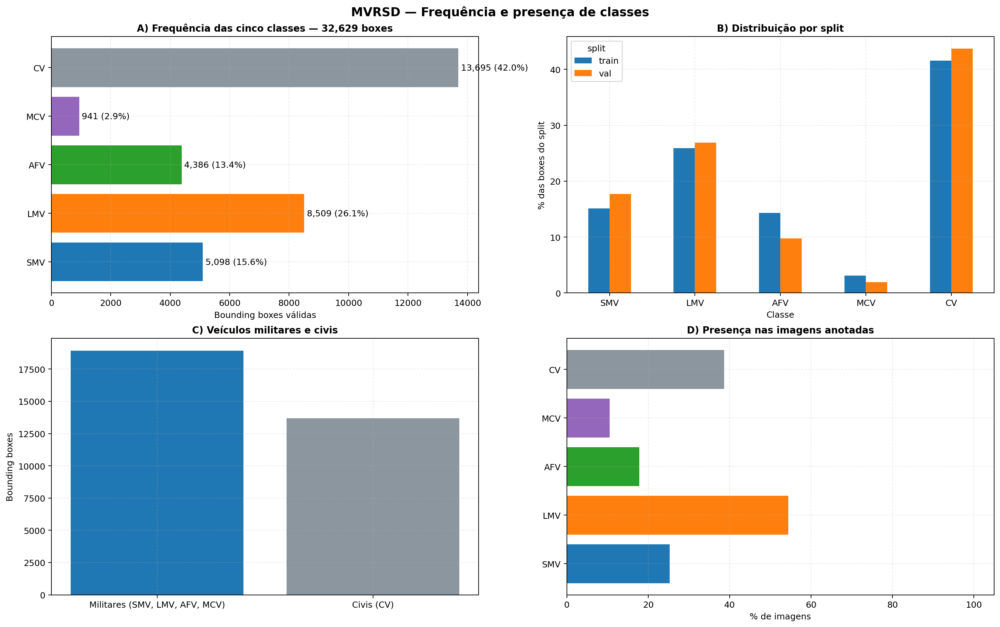

In [3]:
freq_df = pd.read_csv(OUT_DIR / "mvrsd_class_frequencies.csv")
display(freq_df.round(3))
display(IPyImage(filename=str(FIG_DIR / "01_class_frequencies.png"), width=1150))


---
## 2. Tamanho das Bounding Boxes, Escalas COCO e Razão de Aspecto

O tamanho aparente dos veículos determina quantos detalhes ficam disponíveis para a detecção e para o recorte usado na similaridade. Aqui, observamos tanto as dimensões em pixels quanto a parcela da imagem ocupada por cada caixa.

### Principais Observações
- **Predomínio de caixas médias:** 81,28% das anotações são *Medium* pelo critério COCO. As caixas *Small* representam 16,09%, e as *Large*, 2,62%.
- **Limites de área usados:** *Small* < 32² pixels²; *Medium* entre 32² e 96² pixels²; *Large* ≥ 96² pixels².

As dimensões medianas por classe são:

- **`SMV`:** 38 × 39 pixels, com área relativa mediana de **0,325%**.
- **`LMV`:** 56 × 61 pixels, com área relativa mediana de **0,747%**.
- **`AFV`:** 50 × 56 pixels, com área relativa mediana de **0,615%**.
- **`MCV`:** 48 × 57 pixels, com área relativa mediana de **0,624%**.
- **`CV`:** 36 × 39 pixels, com área relativa mediana de **0,312%**.

LMV apresenta as maiores dimensões medianas. SMV e CV ficam próximos em tamanho, o que mostra por que a aparência também importa na distinção dessas categorias. Os grupos *Small*, *Medium* e *Large* descrevem a área da caixa em pixels, enquanto SMV e LMV são categorias definidas pelos autores do dataset.

As medidas abaixo consideram a parte visível da caixa dentro da imagem. As coordenadas originais também são preservadas no CSV para conferência.

,class_name,objects,median_width_px,median_height_px,median_rel_area_pct,median_aspect_ratio,small_pct,medium_pct,large_pct
0,SMV,5098,38.0,39.0,0.3247,0.9600,20.7140,79.1095,0.1765
1,LMV,8509,56.0,61.0,0.7471,0.8429,3.5257,88.3418,8.1326
2,AFV,4386,50.0,56.0,0.6152,0.8533,3.0780,95.2348,1.6872
3,MCV,941,48.0,57.0,0.6240,0.8148,2.2317,96.3868,1.3815
4,CV,13695,36.0,39.0,0.3125,0.9048,27.3019,72.2015,0.4965


Escala COCO (%): {'Small (<32² px)': 16.093046063317907, 'Medium (32²–96² px)': 81.28352079438537, 'Large (≥96² px)': 2.62343314229673}


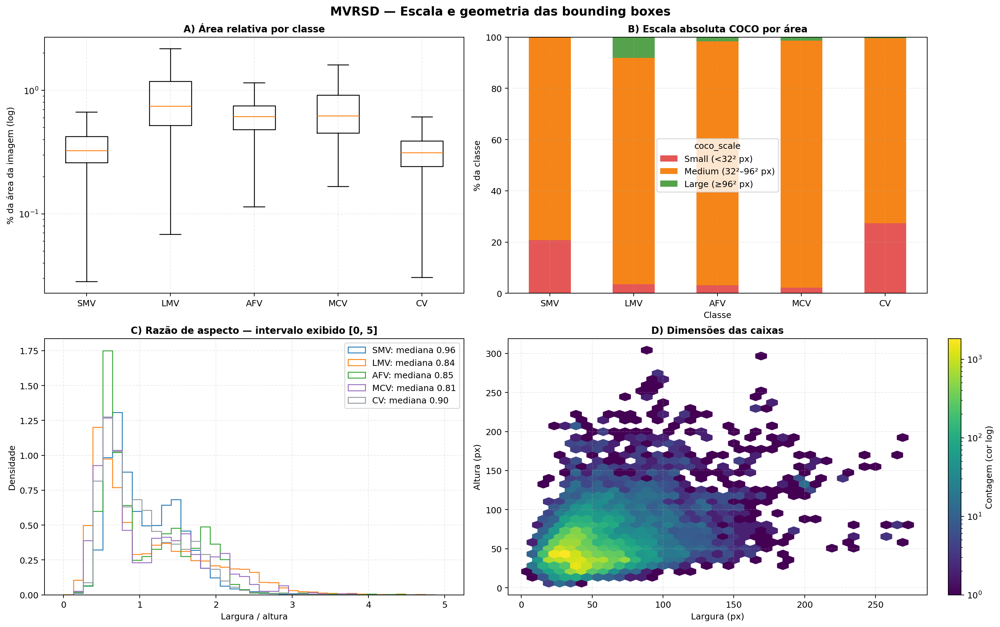

In [4]:
size_df = pd.read_csv(OUT_DIR / "mvrsd_box_sizes.csv")
display(size_df.round(4))
print("Escala COCO (%):", eda_summary["bbox_sizes_and_scales"]["coco_scale_pct"])
display(IPyImage(filename=str(FIG_DIR / "02_bbox_sizes_and_scales.png"), width=1150))


---
## 3. Resoluções de Imagem, Densidade por Cena e Distribuição Espacial

Quase todo o conjunto segue a resolução de **640 × 640 pixels** descrita pelos autores: são **2.996 imagens** nesse formato. As outras quatro apresentam pequenas diferenças nas dimensões.

### Principais Observações
- A média é de **10,88 veículos por imagem**, mas a mediana é de apenas **6**.
- Em **90% das imagens**, a contagem chega a **27 veículos**. A cena mais povoada contém **119**.
- A média acima da mediana mostra o efeito das cenas com muitos veículos sobre a distribuição.

O histograma ajuda a distinguir as cenas mais vazias das concentrações de veículos. O mapa de calor mostra onde os centros das caixas aparecem com maior frequência no enquadramento, e o último painel permite comparar a densidade entre treino e validação.

{
  "resolutions": {
    "640×640": 2996,
    "642×640": 1,
    "641×638": 1,
    "640×643": 1,
    "642×639": 1
  },
  "objects_per_image": {
    "mean": 10.876333333333333,
    "median": 6.0,
    "p90": 27.0,
    "max": 119
  }
}


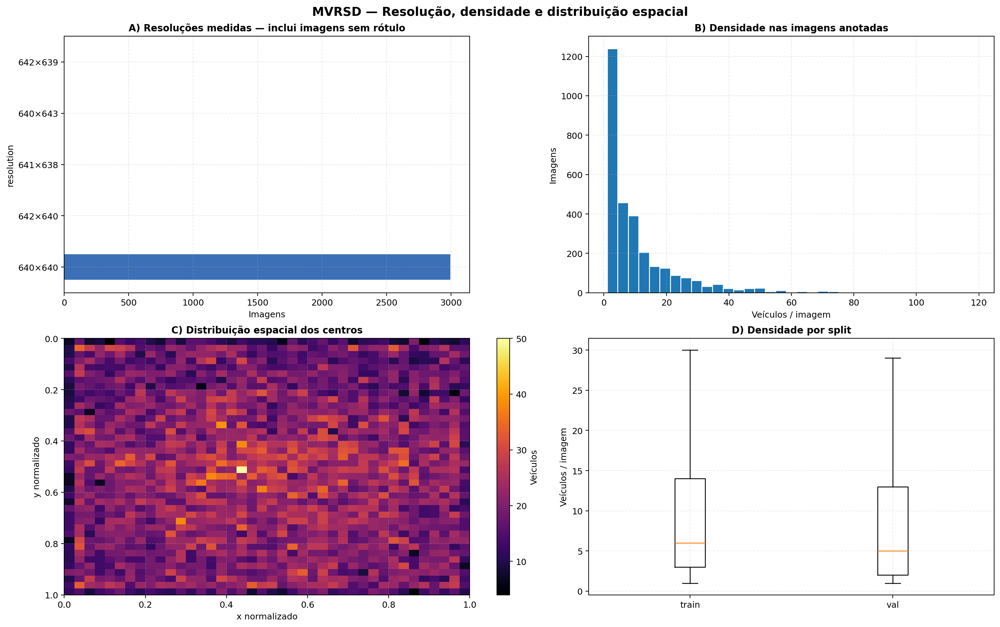

In [5]:
print(json.dumps(eda_summary["resolutions_and_density"], indent=2, ensure_ascii=False))
display(IPyImage(filename=str(FIG_DIR / "03_resolutions_and_scene_density.png"), width=1150))


---
## 4. Oclusão, Truncamento e Qualidade das Anotações

Nesta parte, conferimos quais informações acompanham as caixas e como elas ajudam a interpretar os exemplos mais difíceis.

### O que foi encontrado
- As **3.000 imagens** têm rótulos XML e TXT correspondentes, sem divergências na quantidade de objetos entre os formatos.
- Os campos `truncated` e `difficult` aparecem nas anotações, mas todos os valores são **zero**. Por isso, eles não permitem separar exemplos fáceis e difíceis neste conjunto.
- O arquivo **não fornece uma classificação de oclusão** equivalente à do VisDrone. Essa característica precisa ser observada nas próprias cenas.
- **1.177 caixas (3,61%)** ultrapassam os limites da imagem. Para medir a área visível, essas caixas são limitadas às bordas; as coordenadas originais ficam em `mvrsd_boxes.csv`.

O painel de proximidade à borda destaca possíveis recortes de veículos. Ele complementa a inspeção visual, mas não substitui um rótulo de truncamento atribuído pelo anotador.

{
  "all_discovered_images": 3003,
  "annotation_formats_used": {
    ".xml": 3000
  },
  "unannotated_images": 0,
  "explicit_negative_images": 0,
  "invalid_geometry_boxes": 0,
  "out_of_bounds_boxes": 1177,
  "exact_duplicate_images": 0,
  "paired_xml_txt_images": 3000,
  "paired_count_mismatches": [],
  "orphan_annotation_images": [],
  "images_outside_selected_splits": [
    "MVRSD_dataset/data/test/test_AUAU030001.tif",
    "MVRSD_dataset/data/test/test_AUAU040001.tif",
    "MVRSD_dataset/data/test/test_RURU020001.tif"
  ]
}
Metadados nativos: {
  "truncated": {
    "boxes_with_field": 32629,
    "values": {
      "0": 32629
    }
  },
  "difficult": {
    "boxes_with_field": 32629,
    "values": {
      "0": 32629
    }
  },
  "occluded": {
    "boxes_with_field": 0,
    "values": {}
  }
}


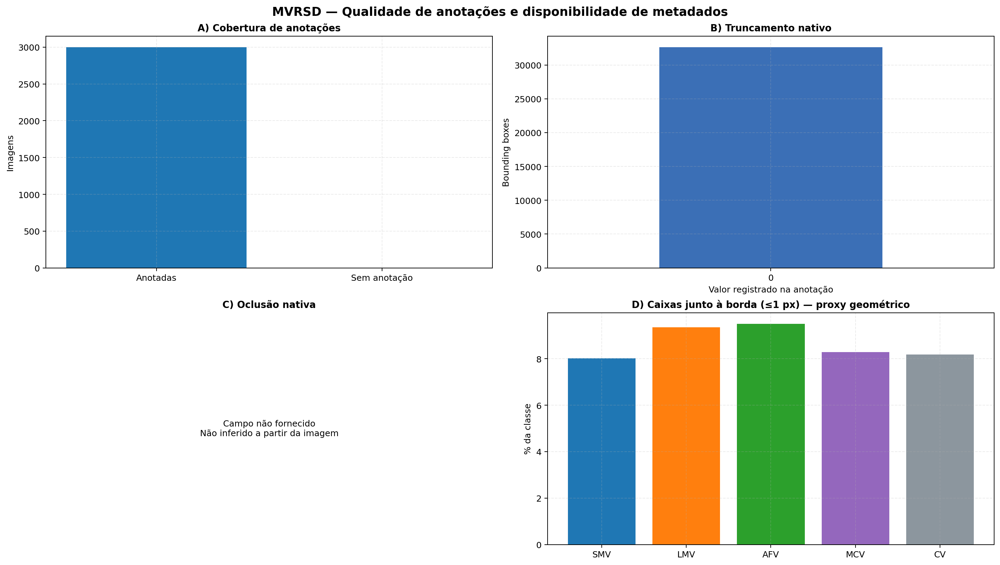

In [6]:
audit = eda_summary["annotation_audit"]
keys = ["all_discovered_images", "annotation_formats_used", "unannotated_images",
        "explicit_negative_images", "invalid_geometry_boxes", "out_of_bounds_boxes",
        "exact_duplicate_images", "paired_xml_txt_images", "paired_count_mismatches",
        "orphan_annotation_images", "images_outside_selected_splits"]
print(json.dumps({key: audit[key] for key in keys}, indent=2, ensure_ascii=False))
print("Metadados nativos:", json.dumps(eda_summary["metadata_availability"], indent=2))
display(IPyImage(filename=str(FIG_DIR / "04_annotation_quality_and_metadata.png"), width=1150))


---
## 5. Cenas Representativas e Resultados Qualitativos dos Detectores

As quatro cenas abaixo mostram diferentes situações do split de validação: variedade de classes, concentração de veículos, objetos pequenos e uma cena com densidade próxima da mediana. Em seguida, três delas são apresentadas lado a lado com as predições do **YOLOv8s/VisDrone** e do **YOLO26s/MVRSD_VIS**.

O contraste mais forte aparece em **`AUAU030523`**. A imagem tem **71 veículos anotados**, e os modelos produzem **27 caixas** e **73 caixas**, respectivamente. Em **`AUAU010003`**, são **27 anotações**, frente a **24 caixas do YOLOv8s** e **30 do YOLO26s**. Na cena menos povoada, **`AUJP010035`**, há **3 veículos**, com **1 caixa do YOLOv8s** e **3 do YOLO26s**.

Essas contagens orientam a leitura das imagens: vale observar os veículos que ficaram sem caixa e as caixas adicionais. Para calcular precisão ou recall, seria necessário conferir a correspondência entre cada predição e cada anotação. Como o MVRSD pode ter participado do treino, usamos esses exemplos para inspecionar o comportamento dos modelos, e não como uma nova validação independente.

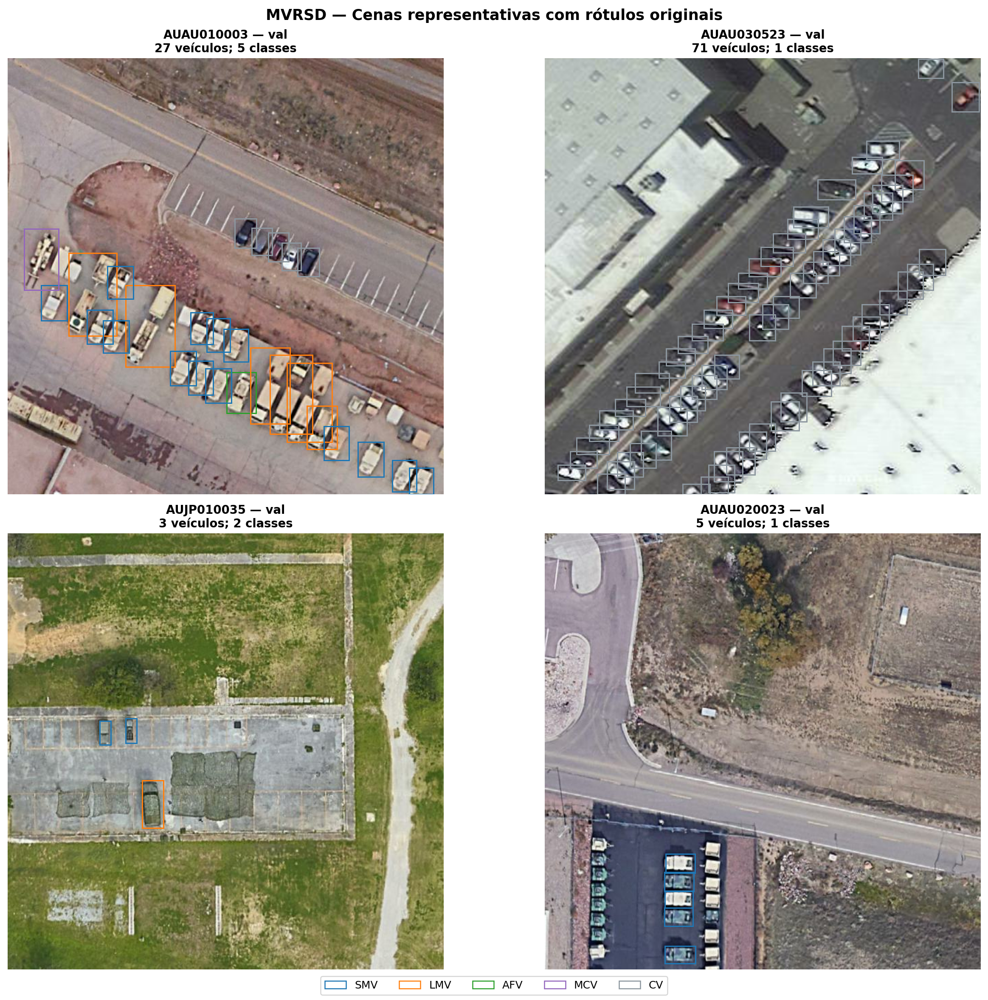

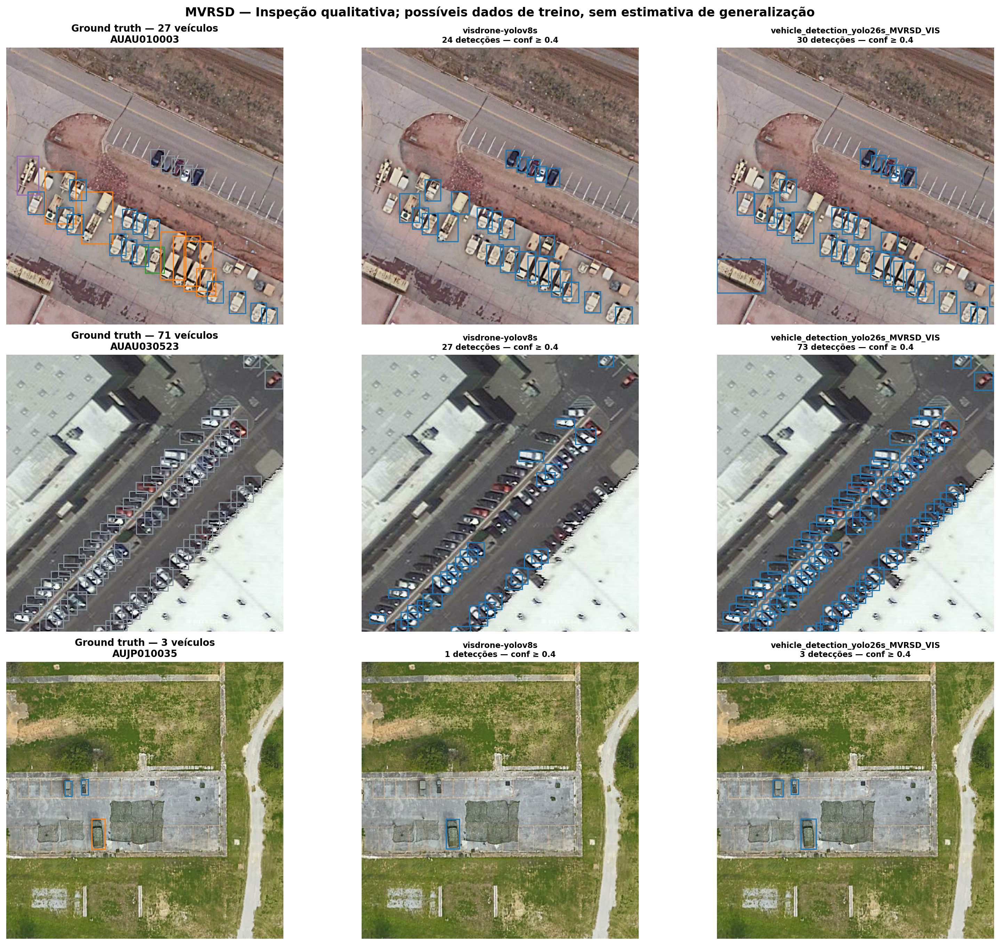

,image_id,configuration,gt_objects,detections,mean_confidence
0,MVRSD_dataset/data/images/val/AUAU010003.jpg,configs/default.yaml,27,24,0.704567
1,MVRSD_dataset/data/images/val/AUAU010003.jpg,configs/yolo26s_mvrsd_vis.yaml,27,30,0.807823
2,MVRSD_dataset/data/images/val/AUAU030523.jpg,configs/default.yaml,71,27,0.636984
3,MVRSD_dataset/data/images/val/AUAU030523.jpg,configs/yolo26s_mvrsd_vis.yaml,71,73,0.744561
4,MVRSD_dataset/data/images/val/AUJP010035.jpg,configs/default.yaml,3,1,0.789053
5,MVRSD_dataset/data/images/val/AUJP010035.jpg,configs/yolo26s_mvrsd_vis.yaml,3,3,0.843807


{
  "configs/default.yaml": {
    "source": "huggingface",
    "file": "visdrone-yolov8s.pt",
    "sha256": "29dae68ac5028cedac1f396333ac89cd9c74232691155243d70d9a1c16cdb24e",
    "repo_id": "dronefreak/visdrone-yolov8s",
    "revision": "cbcca22c6388563fee903e67794dd4ee7755f4a1",
    "requested_revision": "main",
    "filename": "best.pt",
    "device": "cuda",
    "parameters": {
      "provider": "ultralytics",
      "weights": "artifacts/weights/visdrone-yolov8s.pt",
      "huggingface_repo": "dronefreak/visdrone-yolov8s",
      "huggingface_filename": "best.pt",
      "huggingface_revision": "main",
      "vehicle_classes": [
        "car",
        "van",
        "truck",
        "bus"
      ],
      "confidence_threshold": 0.4,
      "iou_threshold": 0.5,
      "image_size": 1280,
      "crop_margin_pixels": 10
    },
    "classes": {
      "0": "pedestrian",
      "1": "people",
      "2": "bicycle",
      "3": "car",
      "4": "van",
      "5": "truck",
      "6": "tricycle",


In [7]:
display(IPyImage(filename=str(FIG_DIR / "05_representative_scenes.png"), width=1100))
qualitative = eda_summary["qualitative_detector"]
if qualitative["status"] == "completed":
    display(IPyImage(filename=str(FIG_DIR / qualitative["figure"]), width=1200))
    display(pd.DataFrame(qualitative["scenes"]))
    print(json.dumps(qualitative["checkpoints"], indent=2, ensure_ascii=False))
else:
    print("Inferência qualitativa desativada por RUN_DETECTOR=False.")


---
## 6. Categorias do MVRSD e Modelos da Galeria Simulada

O detector precisa primeiro localizar o veículo. Depois, o recorte é comparado com as imagens da galeria para identificar um modelo operacional específico.

No MVRSD, um rótulo como **LMV** descreve uma categoria de veículo. Na galeria, rótulos como **`renault_gbc180`** e **`panhard_vbl`** identificam modelos. São níveis diferentes de identificação, mesmo que os dois conjuntos tenham cinco categorias.

A galeria usada no projeto reúne **83 recortes simulados**, distribuídos em:
- **`arquus_vt4`:** 30 imagens, sendo 25 variantes aumentadas;
- **`vltt`:** 19 imagens;
- **`panhard_vbl`:** 13 imagens;
- **`renault_gbc180`:** 13 imagens;
- **`renault_ccfm`:** 8 imagens.

A figura retoma essa distribuição e mostra um exemplo de cada modelo, para relacionar os detalhes presentes nos recortes com as imagens aéreas analisadas acima.

,total,augmented
modelo,,
arquus_vt4,30,25
panhard_vbl,13,0
renault_ccfm,8,0
renault_gbc180,13,0
vltt,19,0


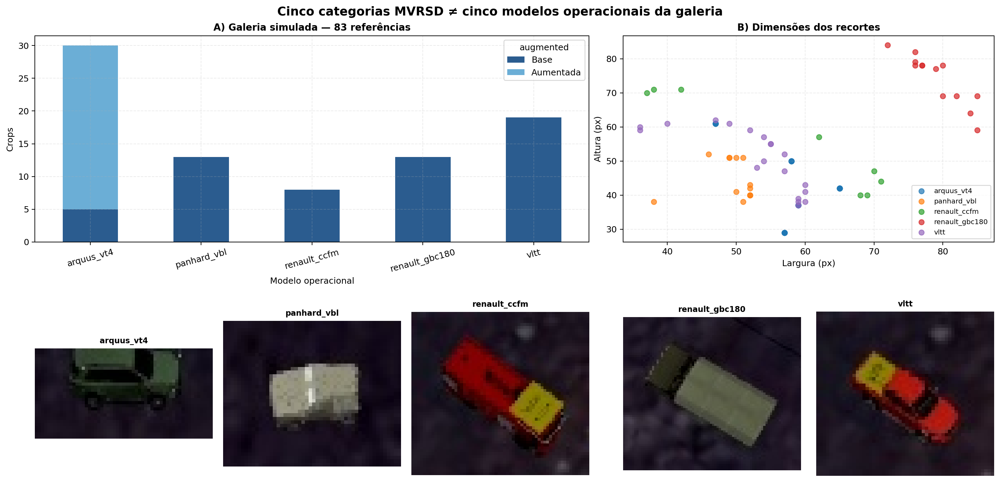

In [8]:
gallery = eda_summary["reference_gallery_overview"]
display(pd.DataFrame.from_dict(gallery["classes"], orient="index").rename_axis("modelo"))
display(IPyImage(filename=str(FIG_DIR / gallery["figure"]), width=1150))


---
## 7. O que a Análise Mostra para o Projeto

O MVRSD acrescenta exemplos de veículos militares às cenas de trânsito analisadas no VisDrone. No conjunto baixado, predominam caixas de escala média, e a quantidade de veículos varia bastante entre as imagens. Ao mesmo tempo, a baixa participação de MCV e a semelhança de tamanho entre algumas categorias mostram dificuldades que a contagem total de objetos, sozinha, não revela.

Os exemplos de detecção ajudam a examinar como os dois checkpoints se comportam nessas cenas. Já a galeria mantém o papel de distinguir modelos específicos a partir dos recortes.

A comparação com o VisDrone continua no notebook **`03_comparacao_visdrone_mvrsd.ipynb`**. As tabelas e figuras desta análise ficam em `outputs/eda_mvrsd/`.

In [9]:
print(f"Análise concluída: {eda_summary['total_images']:,} imagens e {eda_summary['valid_boxes']:,} veículos anotados.")
print("Tabelas disponíveis:")
for path in sorted(OUT_DIR.glob("*.csv")):
    print(" -", path.relative_to(REPO_ROOT))
print("Resumo:", (OUT_DIR / "eda_mvrsd_summary.json").relative_to(REPO_ROOT))
print("Inventário:", (OUT_DIR / "dataset_inventory.json").relative_to(REPO_ROOT))


Análise concluída: 3,000 imagens e 32,629 veículos anotados.
Tabelas disponíveis:
 - outputs/eda_mvrsd/mvrsd_box_sizes.csv
 - outputs/eda_mvrsd/mvrsd_boxes.csv
 - outputs/eda_mvrsd/mvrsd_class_frequencies.csv
 - outputs/eda_mvrsd/mvrsd_images_summary.csv
Resumo: outputs/eda_mvrsd/eda_mvrsd_summary.json
Inventário: outputs/eda_mvrsd/dataset_inventory.json
